In [1]:
import numpy as np
import numpy.linalg as la
import scipy.linalg as sla
import matplotlib.pyplot as plt
%matplotlib inline

from matplotlib import animation,rc
from IPython.display import HTML


# Finite Difference Methods

## Motivation


For a given smooth function $f(x)$, we want to calculate the derivative $f'(x)$ at a given value of $x$.

Suppose we don't know how to compute the analytical expression for $f'(x)$, or it is computationally very expensive. However, we do know how to evaluate the function value $f(x)$.

We know that:

$$ f'(x) = \lim_{h\to 0}\left(\frac{f(x+h)-f(x)}{h}\right) $$

Can we just use

$$ f'(x) \approx \frac{f(x+h)-f(x)}{h} $$

as an approximation? How do we choose $h$? Can we estimate the error of our approximation?

## Finite Difference Method

For a differentiable function $f:\mathbb R\to\mathbb R$,
$$f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}h.$$
For a finite positive step $h$, Taylor expansion about $x$ gives
$$f(x+h)=f(x)+hf'(x)+\frac{h^2}{2}f''(x)+\frac{h^3}{6}f^{(3)}(x)+\cdots.$$
The **forward finite difference** is
$$\boxed{D_h^+f(x)=\frac{f(x+h)-f(x)}h.}$$
If $f\in C^2$ on $[x,x+h]$, Taylor's theorem gives some $\xi_+\in(x,x+h)$ such that
$$D_h^+f(x)-f'(x)=\frac h2f''(\xi_+).$$
Thus $|D_h^+f(x)-f'(x)|\le M_1h$, where $M_1=\tfrac12\max_{[x,x+h]}|f''|$. For an asymptotic bound, choose a fixed neighborhood of $x$ and a uniform bound there. The truncation error is $O(h)$. The notation $df(x)$ in the lecture refers to this derivative approximation, rather than a differential.

The **backward finite difference** follows from expanding $f(x-h)$:
$$f(x-h)=f(x)-hf'(x)+\frac{h^2}{2}f''(x)-\frac{h^3}{6}f^{(3)}(x)+\cdots,$$
$$\boxed{D_h^-f(x)=\frac{f(x)-f(x-h)}h,\qquad D_h^-f(x)-f'(x)=-\frac h2f''(\xi_-).}$$
It is also first order: the error is $O(h)$ if $f''$ is bounded nearby.

Subtract the two expansions. The even powers cancel:
$$f(x+h)-f(x-h)=2hf'(x)+\frac{h^3}{3}f^{(3)}(x)+O(h^5).$$
This expansion with $O(h^5)$ assumes sufficient smoothness, for example $f\in C^5$. The **central finite difference** is
$$\boxed{D_h^0f(x)=\frac{f(x+h)-f(x-h)}{2h}.}$$
Already with $f\in C^3$, Taylor remainder bounds imply
$$|D_h^0f(x)-f'(x)|\le\frac{h^2}{6}\max_{[x-h,x+h]}|f^{(3)}|=O(h^2).$$
Second order describes how the truncation error scales as $h\to0$. It does not promise a smaller total floating point error for every $h$. Near a domain boundary, a one-sided formula may be necessary.

<details>
<summary>Example: Forward, backward, and central formulas</summary>

Approximate $f'(1)$ for $f(x)=x^3$ using $h=0.1$. Compare absolute errors.

<details>
<summary>Solution</summary>

The exact derivative is $3$.
$$D_h^+f(1)=3+3h+h^2=3.31,\qquad D_h^-f(1)=3-3h+h^2=2.71,$$
$$D_h^0f(1)=3+h^2=3.01.$$
The absolute errors are $0.31$, $0.29$, and $0.01$. The leading $O(h)$ terms cancel in the central formula.

</details>
</details>

## Accuracy and Function Evaluations


How accurate is the finite difference approximation? How many function evaluations (in addition to $f(x)$)?

| Method | Approximation | Truncation error | Additional evaluations |
| :--- | :--- | :--- | :---: |
| Forward | $\frac{f(x+h)-f(x)}{h}$ | $O(h)$ | 1 |
| Backward | $\frac{f(x)-f(x-h)}{h}$ | $O(h)$ | 1 |
| Central | $\frac{f(x+h)-f(x-h)}{2h}$ | $O(h^2)$ | 2 |

Our typical trade-off issue! We can get better accuracy with Central Finite Difference with the (possible) increased computational cost.

**How small should the value of $h$ be?**

<details>
<summary>Example: Predicting error reduction</summary>

A forward difference has error approximately $0.008$ at step $h$ in the truncation regime. What happens at $h/4$? What if the method is central?

<details>
<summary>Solution</summary>

A first order error scales by $1/4$, giving approximately $0.002$. For a central first difference with the same initial error and a nonzero $O(h^2)$ leading term, it scales by $1/16$, giving $0.0005$. This prediction does not apply once rounding dominates.

</details>
</details>

## 1. Scalar derivatives: $f:\mathbb R\to\mathbb R$


Suppose you have the function:

$$ f(x) = e^x - 2 $$

and we want to use FD difference method to compute $\frac{df}{dx}$. We will first define the functions to evaluate $f(x)$ and $\frac{df}{dx}(x)$ exactly.

In [2]:
def f(x):
    return np.exp(x) - 2

def df(x):
    return np.exp(x)

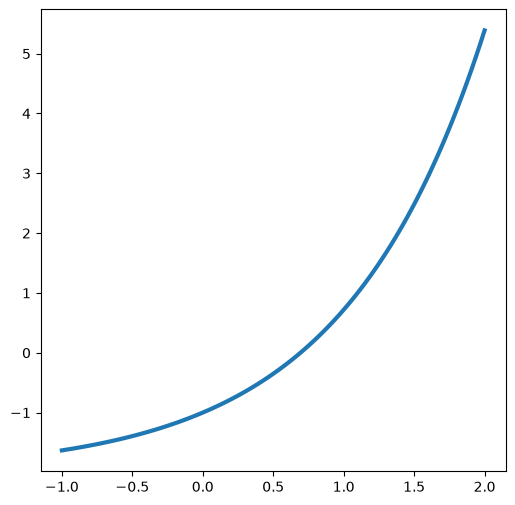

In [3]:
x = np.linspace(-1, 2, 100)
plt.figure(figsize=(6,6))
plt.plot(x, f(x), lw=3)

Let's evaluate the first derivative using finite difference approximation for decreasing values of h. In this example, we want to approximate the derivative at $x = \hat{x} = 1.0$.

In [4]:
xhat = 1.0  # point where we want to find the approximation
h = 1.0     # initial perturbation
errors = []
hs = []

fval = f(xhat)  # we only need to evaluate this once!

# in general, we don't have this value, but we will use it here to visualize the error
dfexact = df(xhat)  

for i in range(20):
    
    # one function evaluation per each perturbation size
    dfapprox = ( f(xhat+h) - fval ) / h   
    
    # get the error
    err = np.abs(dfexact - dfapprox)
    
    print(" %E \t %E " %(h, err) )
    
    hs.append(h)
    errors.append(err)
    
    h = h / 2

 1.000000E+00 	 1.952492E+00 
 5.000000E-01 	 8.085327E-01 
 2.500000E-01 	 3.699627E-01 
 1.250000E-01 	 1.771983E-01 
 6.250000E-02 	 8.674402E-02 
 3.125000E-02 	 4.291906E-02 
 1.562500E-02 	 2.134762E-02 
 7.812500E-03 	 1.064599E-02 
 3.906250E-03 	 5.316064E-03 
 1.953125E-03 	 2.656301E-03 
 9.765625E-04 	 1.327718E-03 
 4.882812E-04 	 6.637511E-04 
 2.441406E-04 	 3.318485E-04 
 1.220703E-04 	 1.659175E-04 
 6.103516E-05 	 8.295707E-05 
 3.051758E-05 	 4.147811E-05 
 1.525879E-05 	 2.073897E-05 
 7.629395E-06 	 1.036945E-05 
 3.814697E-06 	 5.184779E-06 
 1.907349E-06 	 2.592443E-06 


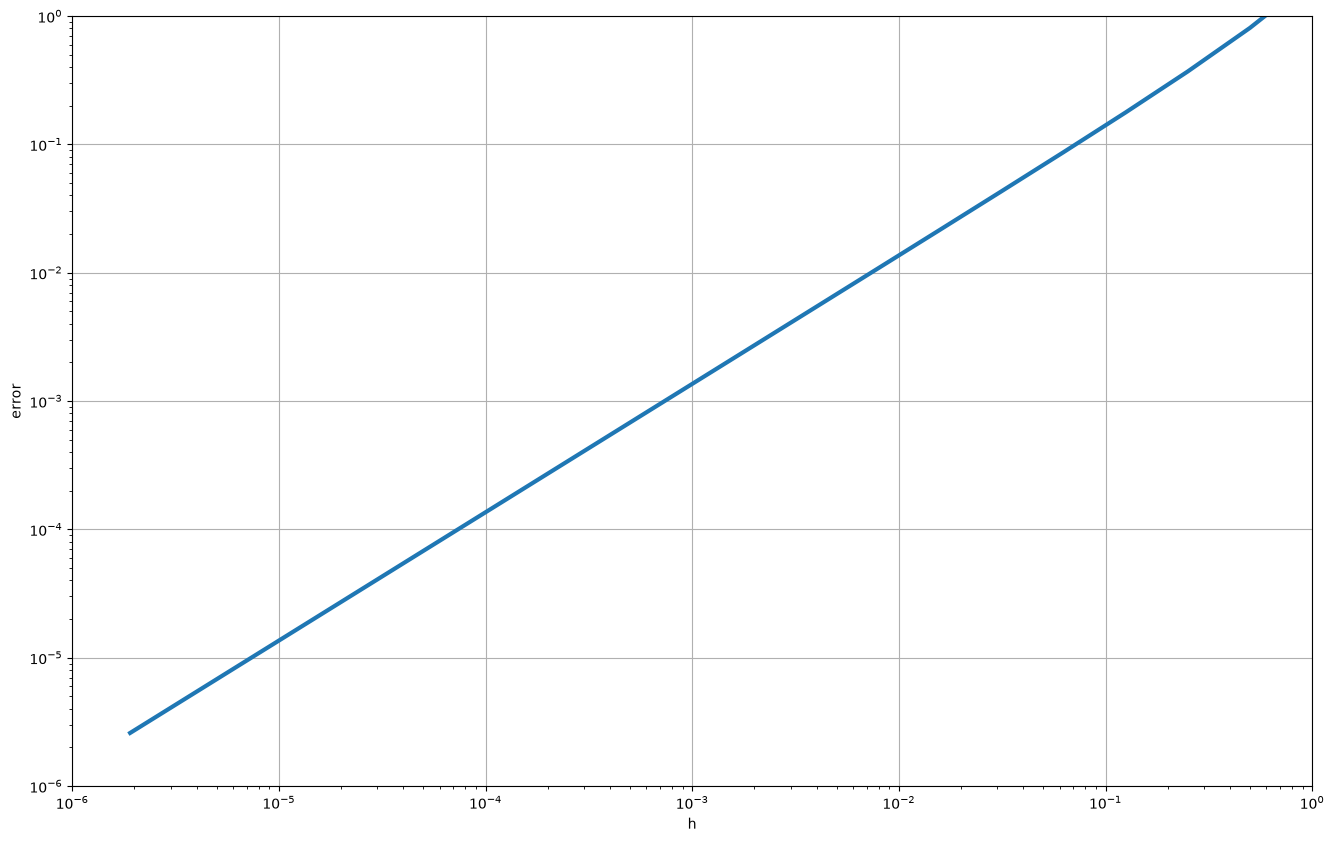

In [5]:
plt.figure(figsize=(16,10))
plt.loglog(hs, errors, lw=3)
plt.xlabel('h')
plt.ylabel('error')
plt.xlim([1e-6,1])
plt.ylim([1e-6,1])
plt.grid()

What happens if we keep decreasing the perturbation h?

In [6]:
xhat = 1.0  # point where we want to find the approximation
h = 1.0     # initial perturbation
errors = []
hs = []

fval = f(xhat)  # we only need to evaluate this once!

# in general, we don't have this value, but we will use it here to visualize the error
dfexact = df(xhat)  

for i in range(80):
    
    # one function evaluation per each perturbation size
    dfapprox = ( f(xhat+h) - fval ) / h   
    
    # get the error
    err = np.abs(dfexact - dfapprox)
    
    print(" %E \t %E " %(h, err) )
    
    hs.append(h)
    errors.append(err)
    
    h = h / 2

 1.000000E+00 	 1.952492E+00 
 5.000000E-01 	 8.085327E-01 
 2.500000E-01 	 3.699627E-01 
 1.250000E-01 	 1.771983E-01 
 6.250000E-02 	 8.674402E-02 
 3.125000E-02 	 4.291906E-02 
 1.562500E-02 	 2.134762E-02 
 7.812500E-03 	 1.064599E-02 
 3.906250E-03 	 5.316064E-03 
 1.953125E-03 	 2.656301E-03 
 9.765625E-04 	 1.327718E-03 
 4.882812E-04 	 6.637511E-04 
 2.441406E-04 	 3.318485E-04 
 1.220703E-04 	 1.659175E-04 
 6.103516E-05 	 8.295707E-05 
 3.051758E-05 	 4.147811E-05 
 1.525879E-05 	 2.073897E-05 
 7.629395E-06 	 1.036945E-05 
 3.814697E-06 	 5.184779E-06 
 1.907349E-06 	 2.592443E-06 
 9.536743E-07 	 1.296275E-06 
 4.768372E-07 	 6.485398E-07 
 2.384186E-07 	 3.253709E-07 
 1.192093E-07 	 1.633208E-07 
 5.960464E-08 	 8.136437E-08 
 2.980232E-08 	 5.156205E-08 
 1.490116E-08 	 3.666089E-08 
 7.450581E-09 	 3.666089E-08 
 3.725290E-09 	 3.666089E-08 
 1.862645E-09 	 1.558702E-07 
 9.313226E-10 	 3.942888E-07 
 4.656613E-10 	 8.254840E-08 
 2.328306E-10 	 8.711259E-07 
 1.164153E

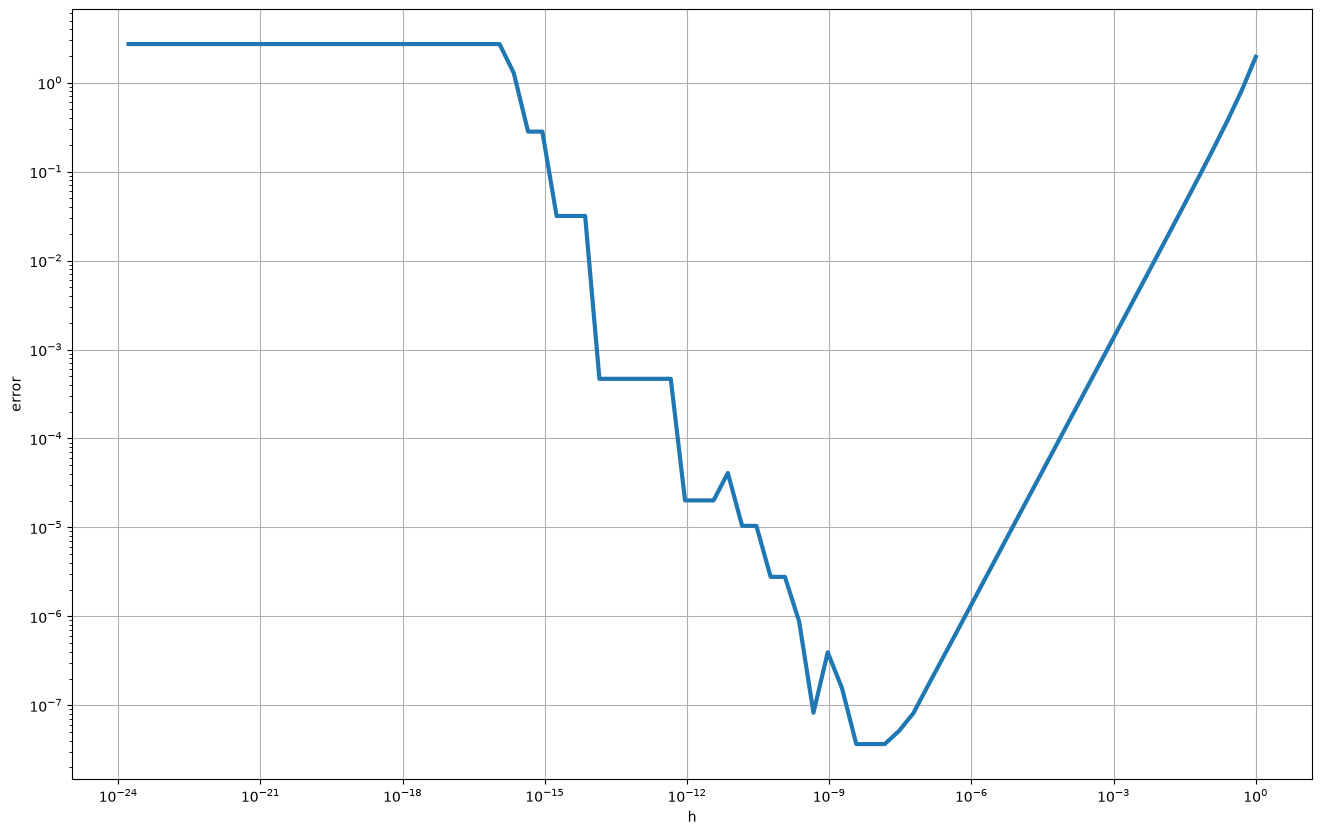

In [7]:
plt.figure(figsize=(16,10))
plt.loglog(hs, errors, lw=3)
plt.xlabel('h')
plt.ylabel('error')
plt.grid()

Not what we expected, correct? If we plot the asymptotic behavior of the truncation error, the error continues to become smaller as the perturbation size decreases:

(1e-16, 100.0)

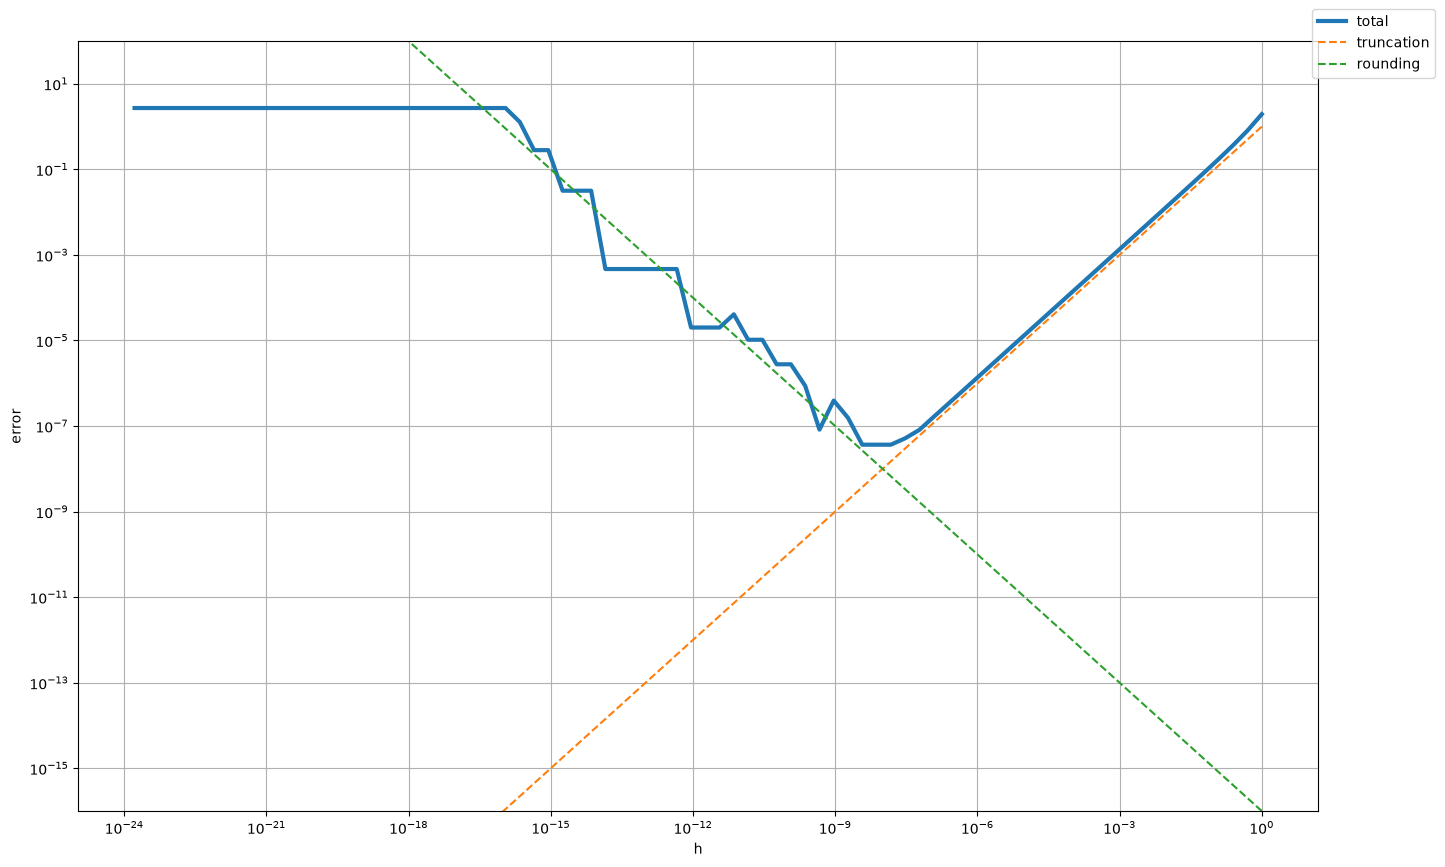

In [8]:
plt.figure(figsize=(16,10))
plt.loglog(hs, errors, lw=3,label='total')
plt.loglog(hs,np.array(hs),'--',label='truncation')
plt.loglog(hs,1e-16/np.array(hs),'--',label='rounding')
plt.legend(bbox_to_anchor=(1.1, 1.05))
plt.xlabel('h')
plt.ylabel('error')
plt.grid()
plt.ylim(1e-16,1e2)

The exact arithmetic truncation error decreases as $h$ decreases. In floating point arithmetic, the computed function values already contain errors. Subtracting nearby values exposes those errors relative to the small difference, and division by $h$ amplifies them. Eventually $x+h$ can round to $x$ itself, producing a zero numerator and a derivative estimate of zero.

Write the computed evaluations as $\widehat f(x+h)=f(x+h)+\eta_+$ and $\widehat f(x)=f(x)+\eta_0$. Before accounting for subtraction and division rounding,
$$\widehat D_h^+f(x)-f'(x)=\underbrace{D_h^+f(x)-f'(x)}_{\text{truncation}}+\underbrace{\frac{\eta_+-\eta_0}{h}}_{\text{evaluation error}}.$$
If $|\eta_+|,|\eta_0|\le\epsilon_m F$, then
$$\left|\frac{\eta_+-\eta_0}{h}\right|\le\frac{2\epsilon_m F}{h}.$$
Here $F$ is a local scale for function evaluation error. The lecture's heuristic uses $F\approx|f(x)|$ and absorbs constants into the error model. Near a zero of $f$, or when the evaluation algorithm itself suffers cancellation, $|f(x)|$ alone may underestimate the error. Input rounding and the arithmetic in the quotient also contribute. This is an approximate model, not a universal bound for every implementation.

## Loss of Accuracy Due to Rounding

For forward differences, use the model
$$E(h)\approx M_1h+\frac{C\epsilon_m F}{h},\qquad M_1>0,\ F>0.$$
The first term decreases with $h$, while the second increases. Differentiating with respect to $h$ gives
$$E'(h)=M_1-\frac{C\epsilon_m F}{h^2},\qquad\boxed{h_{\mathrm{opt}}=\sqrt{\frac{C\epsilon_m F}{M_1}}.}$$
The lecture takes $C=1$ and $F=|f(x)|$, yielding $h=\sqrt{\epsilon_m|f(x)|/M}$. At this model optimum, both terms have equal magnitude. With comparable scales, the usual order is $h\sim\epsilon_m^{1/2}$.

For a method of order $p$,
$$E(h)\approx M_ph^p+\frac{C\epsilon_m F}{h},\qquad\boxed{h_{\mathrm{opt}}=\left(\frac{C\epsilon_m F}{pM_p}\right)^{1/(p+1)}.}$$
Central first differences have $p=2$, so $h\sim\epsilon_m^{1/3}$, and the best modeled error scales as $\epsilon_m^{2/3}$. Forward differences instead give a best modeled error of order $\epsilon_m^{1/2}$. These estimates require nonzero leading constants and suitable scaling.

On a log-log plot of error against $h$, a truncation-dominated first order method has slope $1$, a second order method has slope $2$, and the $1/h$ rounding regime has slope $-1$. An error plateau or irregular curve can occur at machine precision.

<details>
<summary>Example: Balancing truncation and rounding</summary>

Let $E(h)=2h+8\times10^{-16}/h$. Find the minimizing positive step and minimum modeled error.

<details>
<summary>Solution</summary>

Set $E'(h)=2-8\times10^{-16}/h^2=0$. Then
$$h_{\mathrm{opt}}=2\times10^{-8},\qquad E(h_{\mathrm{opt}})=8\times10^{-8}.$$
Each error contribution is $4\times10^{-8}$. A smaller step increases this total model error.

</details>
</details>

<details>
<summary>Example: Rounding error without truncation error</summary>

Why can finite differences fail even for $f(x)=x$, whose exact forward formula is exact for every nonzero $h$?

<details>
<summary>Solution</summary>

In exact arithmetic, $[(x+h)-x]/h=1$. In floating point arithmetic with $x=1$ and a sufficiently small positive step such as $10^{-20}$ in binary64, the stored sum $\operatorname{fl}(1+h)$ equals $1$. The computed quotient is then $0$. There is no Taylor truncation error in this example; input rounding alone destroys the difference.

</details>
</details>

## 2. Gradients: $f:\mathbb R^n\to\mathbb R$

$$ f(\mathbf{x})=f(x_1,x_2,x_3,\ldots,x_n) $$

$$ \nabla f(\mathbf{x})=\begin{bmatrix}\dfrac{\partial f}{\partial x_1}\\\dfrac{\partial f}{\partial x_2}\\\vdots\\\dfrac{\partial f}{\partial x_n}\end{bmatrix} $$

The forward finite difference gradient is

$$ (\nabla f)_{\mathrm{FD}}=\begin{bmatrix}
\dfrac{f(\mathbf{x}+h\boldsymbol{\delta}_1)-f(\mathbf{x})}{h}\\
\dfrac{f(\mathbf{x}+h\boldsymbol{\delta}_2)-f(\mathbf{x})}{h}\\
\vdots\\
\dfrac{f(\mathbf{x}+h\boldsymbol{\delta}_n)-f(\mathbf{x})}{h}
\end{bmatrix},\qquad
\boldsymbol{\delta}_1=\begin{bmatrix}1\\0\\\vdots\\0\end{bmatrix},\quad
\boldsymbol{\delta}_2=\begin{bmatrix}0\\1\\\vdots\\0\end{bmatrix},\quad\ldots,\quad
\boldsymbol{\delta}_i=\begin{bmatrix}0\\\vdots\\1\\\vdots\\0\end{bmatrix}. $$

Here $\boldsymbol\delta_i=\mathbf e_i$ is the $i$th coordinate basis vector. Perturb one coordinate at a time while keeping all other entries fixed:
$$g_i^{\mathrm{FD}}=\frac{f(\mathbf x+h_i\mathbf e_i)-f(\mathbf x)}{h_i}.$$
Cache $f(\mathbf x)$ once. A forward gradient needs $n+1$ scalar function evaluations in total, or $n$ additional evaluations if the baseline is already available. A central gradient needs $2n$ evaluations and does not use the baseline. Perturbing every coordinate together instead approximates the directional derivative $\nabla f(\mathbf x)^T\mathbf 1$, not the gradient vector.

Coordinate scales can differ. A practical starting point is $h_i=\eta\max(1,|x_i|)$, with $\eta$ chosen for the formula and precision. Check that $x_i+h_i\ne x_i$ in floating point arithmetic, and use floating dtype for work arrays.


Suppose you have the function:

$$ f(x_1, x_2) = 2 x_1 + x_1^2 \, x_2 + x_2^3 $$

and we want to use FD difference method to compute $\frac{\partial f}{\partial x_1}$ and $\frac{\partial f}{\partial x_2}$

$$ f(x_1,x_2)=2x_1+x_1^2x_2+x_2^3 $$

$$ \nabla f=\begin{bmatrix}\dfrac{\partial f}{\partial x_1}\\[4pt]\dfrac{\partial f}{\partial x_2}\end{bmatrix}=\begin{bmatrix}2+2x_1x_2\\x_1^2+3x_2^2\end{bmatrix} $$

$$ \nabla f(1.3,4.9)=\begin{bmatrix}14.74\\73.72\end{bmatrix} $$

$$ (\nabla f)_{\mathrm{FD}}=\begin{bmatrix}
\dfrac{f(\mathbf{x}+h\boldsymbol{\delta}_1)-f(\mathbf{x})}{h}\\[8pt]
\dfrac{f(\mathbf{x}+h\boldsymbol{\delta}_2)-f(\mathbf{x})}{h}
\end{bmatrix} $$

<details>
<summary>Example: Two-variable gradient and its error</summary>

For $f(x_1,x_2)=2x_1+x_1^2x_2+x_2^3$, find the forward gradient at $(1.3,4.9)$ using $h=0.05$.

<details>
<summary>Solution</summary>

The exact gradient is $(14.74,73.72)^T$. Expanding each coordinate separately gives
$$g_1^{\mathrm{FD}}=2+2x_1x_2+hx_2=14.985,$$
$$g_2^{\mathrm{FD}}=x_1^2+3x_2^2+3x_2h+h^2=74.4575.$$
The signed errors are $0.245$ and $0.7375$. Only three total evaluations are needed when the baseline is reused.

</details>
</details>

In [9]:
def f(x1,x2):
    return (2*x1 + (x1**2)*x2 + x2**3)

You will need to add a perturbation to each one of the function variables $x_i$. The "ideal" perturbation is not necessarily the same for each variable, but it can be a good starting point. We will perform these computations for $x_1 = 1.3$ and $x_2 = 4.9$, using the Forward Finite Difference Method. The exact solution is:

In [10]:
x1 = 1.3
x2 = 4.9
dfdx1_exact = 2 + 2*x1*x2
dfdx2_exact = x1**2 + 3*x2**2
print(dfdx1_exact,dfdx2_exact)

14.740000000000002 73.72000000000001


In [11]:
h = 0.05
fval = f(x1,x2)

dfx1 = (f(x1+h,x2)-fval)/h
dfx2 = (f(x1,x2+h)-fval)/h

print(dfx1, dfdx1_exact, abs((dfx1-dfdx1_exact)/dfdx1_exact) )
print(dfx2, dfdx2_exact, abs((dfx2-dfdx2_exact)/dfdx2_exact) )

14.984999999999786 14.740000000000002 0.01662143826321467
74.45749999999975 73.72000000000001 0.010004069451976957


For a scalar function of $n$ variables, the gradient has $n$ entries and maps $\mathbb R^n$ to $\mathbb R^n$:
$$\nabla f(\mathbf x)=\begin{bmatrix}\partial f/\partial x_1&\cdots&\partial f/\partial x_n\end{bmatrix}^T.$$
The derivative as a linear map is $Df(\mathbf x)[\mathbf v]=\nabla f(\mathbf x)^T\mathbf v$; its matrix is a $1\times n$ row. We store the gradient as a one dimensional NumPy array.

For the next example,
$$f(x_1,x_2,x_3)=2x_1x_3+x_1^2x_2+x_2^3+6x_3^2.$$
The code accepts all coordinates in a single vector.

In [12]:
def f(xvec):
    return (2*xvec[0]*xvec[2] + (xvec[0]**2)*xvec[1] + xvec[1]**3 + 6*xvec[2]**2)

In general, for a function $f(\bf x)$, the derivative can be expressed as:

    
$$ \nabla f = \begin{bmatrix} \frac{\partial f}{\partial x_1}\\\frac{\partial f}{\partial x_2}\\...\\ \frac{\partial f}{\partial x_n} \end{bmatrix} $$

which is called the **gradient** of $f$. The exact array can be obtained using:

In [13]:
def gradf(xvec):
    x1,x2,x3 = xvec
    df1 = 2*x3 + 2*x1*x2
    df2 = x1**2 + 3*x2**2
    df3 = 2*x1 + 12*x3
    return np.array([df1,df2,df3])

We will perform our computation using:

In [14]:
xvec = np.array([4.1, 3.3, 15.8])

Remember that we need to add the perturbation one entry at a time! We should also compute the function value for the unperturbed variables only once.

In [15]:
fval = f(xvec)
print(fval)

1718.8100000000002


In [16]:
h = 0.1
df_grad = np.zeros_like(xvec)
for i in range(len(xvec)):
    xfd = xvec.copy()
    xfd[i] += h
    df_grad[i] = (f(xfd) - fval)/h

print(df_grad)
print(gradf(xvec))

[ 58.99  50.48 198.4 ]
[ 58.66  49.48 197.8 ]


<details>
<summary>Example: Gradient error experiment</summary>

For $f(\mathbf x)=2x_1x_3+x_1^2x_2+x_2^3+6x_3^2$, write the analytical gradient and describe how to compare forward differences for a sequence of positive steps. Use $\mathbf x=(4.1,3.3,15.8)^T$ as a concrete test.

<details>
<summary>Solution</summary>

The analytical gradient is
$$\nabla f=\begin{bmatrix}2x_3+2x_1x_2\\x_1^2+3x_2^2\\2x_1+12x_3\end{bmatrix},\qquad\nabla f(4.1,3.3,15.8)=\begin{bmatrix}58.66\\49.48\\197.8\end{bmatrix}.$$
For each step $h$, compute a new gradient by perturbing each coordinate separately, then record $\|\mathbf g_h-\nabla f\|_2$. Allocate a floating array for the gradient and never alter the original input vector. In exact arithmetic, this polynomial gives
$$\mathbf g_h-\nabla f=\begin{bmatrix}x_2h\\3x_2h+h^2\\6h\end{bmatrix}.$$
A log-log error plot therefore initially follows first order behavior and may turn upward when rounding dominates. Use the same error norm for all steps.

</details>
</details>

## 3. Jacobians: $\mathbf f:\mathbb R^n\to\mathbb R^m$


Suppose you have the function ${\bf f}({\bf x})$ where ${\bf x} \in R^n$:

$$ {\bf f}({\bf x}) =  \begin{bmatrix} f_1({\bf x})\\f_2({\bf x})\\ ... \\f_m({\bf x}) \end{bmatrix} =\begin{bmatrix}
f_1(x_1,x_2,\ldots,x_n)\\f_2(x_1,x_2,\ldots,x_n)\\\vdots\\f_m(x_1,x_2,\ldots,x_n)
\end{bmatrix} $$

The derivative of this function is:

$$ {\bf J}({\bf x}) =\begin{bmatrix}
\dfrac{\partial f_1}{\partial x_1}&\dfrac{\partial f_1}{\partial x_2}&\cdots&\dfrac{\partial f_1}{\partial x_n}\\
\dfrac{\partial f_2}{\partial x_1}&\dfrac{\partial f_2}{\partial x_2}&\cdots&\dfrac{\partial f_2}{\partial x_n}\\
\vdots&\vdots&\ddots&\vdots\\
\dfrac{\partial f_m}{\partial x_1}&\dfrac{\partial f_m}{\partial x_2}&\cdots&\dfrac{\partial f_m}{\partial x_n}
\end{bmatrix}
=\begin{bmatrix}\dfrac{\partial\mathbf{f}}{\partial x_1}&\cdots&\dfrac{\partial\mathbf{f}}{\partial x_n}\end{bmatrix}. $$

which is known as the **Jacobian** matrix.

Here is another example:

The Jacobian has **$m$ rows and $n$ columns**: rows index outputs, columns index input coordinates. Its forward approximation is
$$J_{:,j}^{\mathrm{FD}}=\frac{\mathbf f(\mathbf x+h_j\mathbf e_j)-\mathbf f(\mathbf x)}{h_j}.$$
One perturbed vector evaluation supplies an entire column. The total is $n+1$ vector function evaluations, or $n$ additional evaluations with a cached baseline. If one instead counts each scalar component evaluation, the corresponding count is $m(n+1)$. A central Jacobian uses $2n$ vector evaluations. For a scalar output, the Jacobian is $\nabla f^T$.

For small $\mathbf s$, $\mathbf f(\mathbf x+\mathbf s)\approx\mathbf f(\mathbf x)+J(\mathbf x)\mathbf s$. This linearization explains the column orientation.

In [17]:
def fn(xvec):
    f1 = 2*xvec[0]*xvec[2] + (xvec[0]**2)*xvec[1] + xvec[1]**3 + 6*xvec[2]**2
    f2 = xvec[0]*xvec[1]*xvec[2]   
    return np.array([f1,f2])

In [18]:
xvec = np.array([42.1, 33.3, 15.8])

In [19]:
fn(xvec)

array([98775.49 , 22150.494])

The exact Jacobian is:

In [20]:
def Jacobianf(xvec):
    x1,x2,x3 = xvec
    df1dx1 = 2*x3 + 2*x1*x2
    df1dx2 = x1**2 + 3*x2**2
    df1dx3 = 2*x1 + 12*x3
    df2dx1 = x2*x3
    df2dx2 = x1*x3
    df2dx3 = x2*x1
    return np.array([[df1dx1,df1dx2,df1dx3],[df2dx1,df2dx2,df2dx3]])   

In [21]:
Jacobianf(xvec)

array([[2835.46, 5099.08,  273.8 ],
       [ 526.14,  665.18, 1401.93]])

Using finite difference method:

In [22]:
h = 0.001
m = 2
n = 3
Jac = np.zeros((m,n))
fvaln = fn(xvec)

for i in range(n):
    xfd = xvec.copy()
    xfd[i] += h
    Jac[:,i] = (fn(xfd) - fvaln)/h

print(Jac)
print(Jacobianf(xvec))

[[2835.49329999 5099.17990098  273.80599998]
 [ 526.14        665.18       1401.93      ]]
[[2835.46 5099.08  273.8 ]
 [ 526.14  665.18 1401.93]]


<details>
<summary>Example: Jacobian dimensions and evaluation cost</summary>

Let
$$\mathbf f(x_1,x_2,x_3)=\begin{bmatrix}2x_1x_3+x_1^2x_2+x_2^3+6x_3^2\\x_1x_2x_3\end{bmatrix}.$$
Find its Jacobian and the total number of vector evaluations needed for a forward approximation.

<details>
<summary>Solution</summary>

There are two outputs and three inputs, so
$$J=\begin{bmatrix}2x_3+2x_1x_2&x_1^2+3x_2^2&2x_1+12x_3\\x_2x_3&x_1x_3&x_1x_2\end{bmatrix}\in\mathbb R^{2\times3}.$$
Evaluate the baseline once and perturb each of the three inputs once: four vector evaluations total. Store each difference in a column, as in `Jac[:, i]`.

</details>
</details>

## Practice: Finite Difference Calculations

<details>
<summary>Example: Relative error for an exponential</summary>

For $f(x)=6e^x$, approximate $f'(0.7)$ by a forward difference with $h=0.07$ and calculate the relative error.

<details>
<summary>Solution</summary>

The exact derivative is $6e^{0.7}$. The approximation is
$$D_h^+f(0.7)=6e^{0.7}\frac{e^{0.07}-1}{0.07}.$$
The relative error is
$$\frac{|D_h^+f(0.7)-6e^{0.7}|}{|6e^{0.7}|}=\left|\frac{e^{0.07}-1}{0.07}-1\right|\approx\boxed{0.0358311607745}.$$
This is approximately $3.5831\%$, not $0.0358\%$. Relative error is undefined if the exact derivative is zero.

</details>
</details>

<details>
<summary>Example: Forward gradient of a velocity field</summary>

For $v(x,y,z)=x^2yz+xz+yz$, compute the forward difference approximation to $\nabla v$ at $(1,1,1)^T$ with $h=0.1$.

<details>
<summary>Solution</summary>

The analytical gradient is
$$\nabla v=\begin{bmatrix}2xyz+z\\x^2z+z\\x^2y+x+y\end{bmatrix},\qquad\nabla v(1,1,1)=\begin{bmatrix}3\\2\\3\end{bmatrix}.$$
The baseline is $v(1,1,1)=3$. The perturbed values are $3.31$, $3.2$, and $3.3$, respectively. Thus
$$\boxed{\nabla v_{\mathrm{FD}}=\begin{bmatrix}3.1\\2\\3\end{bmatrix}.}$$
Only the $x$ component has truncation error here because the function is linear in $y$ and $z$ with other inputs fixed.

</details>
</details>

<details>
<summary>Example: Velocity from particle position</summary>

A particle has position $x(t)=t^2+c$, where $c$ is constant. Select a formula with the best truncation order among forward, backward, and central first differences. Approximate the velocity at $t_0=0.8$ using $h=0.02$.

<details>
<summary>Solution</summary>

Central differences have second order truncation error for general smooth functions. For this quadratic they are exact in exact arithmetic:
$$\frac{x(t_0+h)-x(t_0-h)}{2h}=\frac{(t_0+h)^2-(t_0-h)^2}{2h}=2t_0=\boxed{1.6}.$$
The constant $c$ cancels. Forward differences give $2t_0+h=1.62$ and backward differences give $2t_0-h=1.58$. Floating point rounding can still occur in all three formulas.

</details>
</details>

<details>
<summary>Example: Programming a gradient error study</summary>

For
$$f(\mathbf x)=2x_1^2-0.5x_1x_2+5x_2^3,$$
implement `func(x)`, the analytical gradient `dfunc(x)`, and a forward gradient `fd(x, dx)`. Given a floating vector `xvec` of length two and positive perturbations `dxvec`, store
$$\texttt{error}[k]=\|\texttt{fd(xvec, dxvec[k])}-\texttt{dfunc(xvec)}\|_\infty.$$
The array `error` must have the same shape as `dxvec`. Plot error against perturbation size.

<details>
<summary>Solution</summary>

The analytical gradient is
$$\nabla f=\begin{bmatrix}4x_1-0.5x_2\\-0.5x_1+15x_2^2\end{bmatrix}.$$
The infinity norm is the largest absolute component error. Cache the baseline once within each `fd` call, perturb one coordinate at a time, and leave the input unchanged.

```python
def func(x):
    x1, x2 = x
    return 2*x1**2 - 0.5*x1*x2 + 5*x2**3

def dfunc(x):
    x1, x2 = x
    return np.array([4*x1 - 0.5*x2, -0.5*x1 + 15*x2**2])

def fd(x, dx):
    point = np.asarray(x, dtype=float)
    f0 = func(point)
    return np.array([
        (func(point + dx*direction) - f0)/dx
        for direction in np.eye(point.size)
    ])

error = np.array([
    np.linalg.norm(fd(xvec, dx) - dfunc(xvec), ord=np.inf)
    for dx in dxvec
]).reshape(dxvec.shape)
plt.loglog(dxvec, error)
plt.xlabel('Perturbation size')
plt.ylabel('Infinity norm of gradient error')
plt.show()
```

In exact arithmetic the component errors are $2h$ and $15x_2h+5h^2$. First order behavior is expected when the leading term dominates; very small steps can amplify rounding. The concrete experiment below uses $(1.3,4.9)^T$ so it can run independently of externally supplied variables.

</details>
</details>

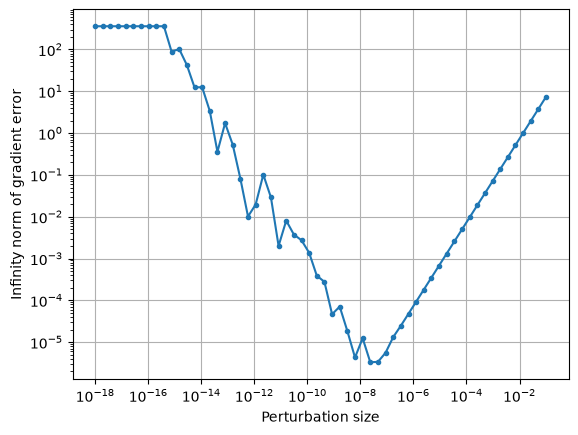

In [23]:
def func(x):
    x1, x2 = x
    return 2*x1**2 - 0.5*x1*x2 + 5*x2**3

def dfunc(x):
    x1, x2 = x
    return np.array([4*x1 - 0.5*x2, -0.5*x1 + 15*x2**2])

def fd(x, dx):
    point = np.asarray(x, dtype=float)
    f0 = func(point)
    return np.array([(func(point + dx*e) - f0)/dx for e in np.eye(point.size)])

practice_xvec = np.array([1.3, 4.9])
practice_dxvec = np.logspace(-1, -18, 60)
practice_error = np.array([
    la.norm(fd(practice_xvec, step) - dfunc(practice_xvec), ord=np.inf)
    for step in practice_dxvec
])
plt.loglog(practice_dxvec, practice_error, 'o-', markersize=3)
plt.xlabel('Perturbation size')
plt.ylabel('Infinity norm of gradient error')
plt.grid(True)
plt.show()

# Diffusion Equation with Finite Differences

The time dependent diffusion equation models the cooling of a rod:
$$\frac{\partial u}{\partial t}=D\frac{\partial^2u}{\partial x^2},\qquad -1<x<1,\quad t>0,$$
where $u(x,t)$ is temperature and $D>0$ is thermal diffusivity.

Use homogeneous Dirichlet boundary conditions
$$u(-1,t)=u(1,t)=0,$$
and initial temperature $u(x,0)=0.5$ for $-1<x<1$. The endpoint values are set to zero from the initial stored state onward. The constant interior initial data and zero boundary values have a jump at the two space-time corners; the PDE smooths the interior profile for positive time.

Use a uniform grid $x_i=-1+i\Delta x$, $i=0,\ldots,N$, with $\Delta x=2/N$, and $t^{(j)}=j\Delta t$. Write $u_i^{(j)}\approx u(x_i,t^{(j)})$.

Backward difference in time and central second difference in space give
$$\frac{u_i^{(j)}-u_i^{(j-1)}}{\Delta t}=D\frac{u_{i+1}^{(j)}-2u_i^{(j)}+u_{i-1}^{(j)}}{(\Delta x)^2}.$$
For a smooth exact solution, the derivative approximation errors are $O(\Delta t)$ and $O((\Delta x)^2)$, respectively. The second spatial derivative formula follows by adding the Taylor expansions at $x_i\pm\Delta x$:
$$u(x_i+\Delta x,t)-2u(x_i,t)+u(x_i-\Delta x,t)=(\Delta x)^2u_{xx}+\frac{(\Delta x)^4}{12}u_{xxxx}+\cdots.$$
Define $r=D\Delta t/(\Delta x)^2$. Rearranging yields
$$\boxed{-r u_{i-1}^{(j)}+(1+2r)u_i^{(j)}-r u_{i+1}^{(j)}=u_i^{(j-1)}.}$$
All three spatial values are taken at the new time level, so this is an **implicit** scheme: each step requires a linear solve.

Store all $N+1$ grid values, including the endpoints:
$$\mathbf u_{\mathrm{full}}^{(j)}=[0,u_1^{(j)},\ldots,u_{N-1}^{(j)},0]^T.$$
The unknown vector in the linear system consists only of the $N-1$ interior values:
$$\boxed{A\mathbf u_{\mathrm{int}}^{(j)}=\mathbf u_{\mathrm{int}}^{(j-1)},\qquad A=I+rB,}$$
$$B=\begin{bmatrix}2&-1&&0\\-1&2&\ddots&\\&\ddots&\ddots&-1\\0&&-1&2\end{bmatrix}.$$
Thus $A$ has diagonal $1+2r$ and adjacent diagonals $-r$. Nonzero Dirichlet boundary values would add $r u_0^{(j)}$ to the first right-hand entry and $r u_N^{(j)}$ to the last; both are zero here.

<details>
<summary>Example: Assembling an implicit diffusion step</summary>

Use $N=4$ intervals on $[-1,1]$, $D=0.1$, and $\Delta t=0.05$. Form the matrix for the interior temperatures.

<details>
<summary>Solution</summary>

There are five grid points but only three interior unknowns. Since $\Delta x=0.5$, $r=0.02$, and
$$A=\begin{bmatrix}1.04&-0.02&0\\-0.02&1.04&-0.02\\0&-0.02&1.04\end{bmatrix}.$$
The first right-hand vector is $(0.5,0.5,0.5)^T$. Solve $A\mathbf u^{(1)}_{\mathrm{int}}=\mathbf u^{(0)}_{\mathrm{int}}$, then append a zero endpoint on each side. Using $\Delta x$ rather than $(\Delta x)^2$ would produce the wrong stencil coefficient.

</details>
</details>

Since we are only solving for the $N-1$ "internal" points, we need to construct a matrix with dimensions $N-1 \times N-1$. We will use the following parameters:

In [24]:
N = 50                      # number of spacing (intervals)
x = np.linspace(-1,1,N+1)   # these are the discretized points (and so we have N + 1 points)
dx = x[1] - x[0]

D = 0.1              # thermal diffusivity
dt = 0.05            # time increment
timesteps = 400      # number of timesteps
u0 = 0.5             # initial temperature in the rod

utotal = np.zeros((x.shape[0],timesteps+1))  # to store all the temperatures

Write the initial vector  $\mathbf{u}({\bf x},t^0) = \mathbf{u}_0$ (initial condition)

In [25]:
ut0 = np.concatenate(([0.0], u0*np.ones(N-1), [0.0]))

Update the first column of `utotal` using `ut0`

In [26]:
utotal[:,0] = ut0

Build the FD matrix ${\bf A}$. 

In [27]:
B = np.diag(2*np.ones(N-1)) - np.diag(np.ones(N-2),1) - np.diag(np.ones(N-2),-1)
A = np.eye(N-1) + D*(dt/(dx**2))*B

Use `plt.spy` to see structure of the matrix

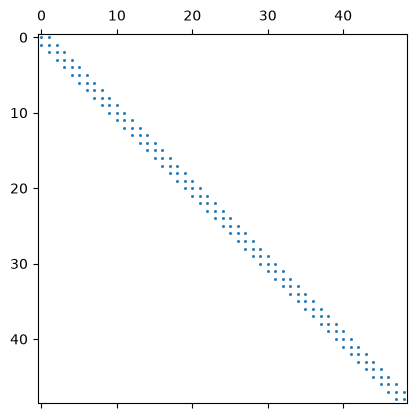

In [28]:
plt.spy(A,markersize = 1)

The matrix $A$ is symmetric positive definite and tridiagonal. For any nonzero interior vector $\mathbf v$, extended by $v_0=v_N=0$,
$$\mathbf v^TB\mathbf v=\sum_{i=0}^{N-1}(v_{i+1}-v_i)^2>0.$$
Consequently the linear solve has a unique solution. A dense solve is simple for this small example; a tridiagonal solver uses $O(N)$ work and storage, while a general dense factorization uses $O(N^3)$ work and $O(N^2)$ storage. Because $A$ is constant across time steps, its factorization can also be reused.

Backward Euler damps every eigenmode: if $B\mathbf v=\lambda\mathbf v$ with $\lambda>0$, each time step multiplies that mode by $1/(1+r\lambda)\in(0,1)$. The scheme is unconditionally stable for this linear diffusion problem, but large time steps can still be inaccurate. For sufficiently smooth solutions the method is first order in time and second order in space. The incompatible corner data can reduce observed accuracy near $t=0$.

In [29]:
for i in range(timesteps):
    u_old = utotal[:,i]
    b = u_old[1:-1]  # remove the boundary conditions
    u_new = sla.solve(A,b)
    utotal[:,i+1] = np.append(0,np.append(u_new,0)) # add back the boundary condition

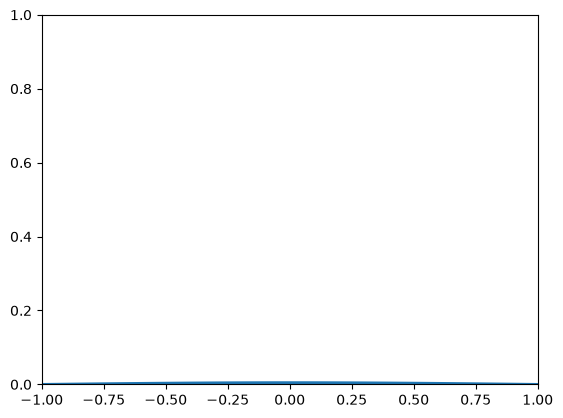

In [30]:
fig,ax = plt.subplots()
ax.set_xlim((-1,1))
ax.set_ylim((0,1.0))
line, = ax.plot([],[],lw=2)

def init():
    line.set_data([],[])
    return (line,)

def animate(i):
    y = utotal[:,i]
    line.set_data(x,y)
    return (line,)

anim = animation.FuncAnimation(fig, animate, init_func=init,
                               frames=timesteps+1, interval=50, blit=True)

rc('animation',html='html5')
anim